# JSON on the Command Line with jq

Web APIs, cloud tools, container runtimes and structured logs all speak **JSON**. **jq** is a command-line JSON processor: it selects, filters, transforms and aggregates JSON with short expressions, like `sed` and `awk` do for text.

**After this lesson you can:**

1. Select fields and array elements with jq paths.
2. Filter and transform with `select`, `map` and object construction.
3. Aggregate with `group_by`, `length` and `add`.
4. Process real JSON: the notebooks of this course and JSON logs.

Real data: every `.ipynb` file is a JSON document, so the course itself is a JSON dataset.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

WORK = Path(tempfile.mkdtemp())          # a folder on the Linux file system (not on a Windows drive)
REPO = Path.cwd().parent                 # the course repository: real data for some examples

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def sh(cmd: str, cwd: Path = WORK, quiet: bool = False, check: bool = False) -> Output:
    """Run a command with bash, print the command and its output."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True)
    shorten = lambda t: t.replace(str(WORK), "<work>").replace(str(REPO), "<repo>")
    out = shorten((r.stdout + r.stderr).rstrip())
    if not quiet:
        print(f"$ {shorten(cmd)}" + (f"\n{out}" if out else ""))
    if check and r.returncode:
        raise RuntimeError(f"command failed with exit code {r.returncode}")
    return Output(r.stdout)

## 1. Basic Filters

| Filter | Result |
| :--- | :--- |
| `.` | the whole input (pretty-printed) |
| `.name`, `.a.b` | a field, a nested field |
| `.items[0]`, `.items[-1]` | an array element |
| `.items[]` | every element, one per output |
| `.items \| length` | the number of elements |
| `keys` | the field names of an object |
| `-r` | raw output (strings without quotes) |
| `-c` | compact output (one JSON value per line) |

In [2]:
(WORK / "order.json").write_text("""
{"order_id": "A-1001", "customer": {"name": "Deniz", "city": "Izmir"},
 "items": [{"sku": "pen", "qty": 3, "price": 1.5}, {"sku": "book", "qty": 1, "price": 12.0}],
 "paid": true}
""")
sh("jq . order.json")
sh("jq -r '.customer.name' order.json")
sh("jq '.items | length' order.json")
sh("jq -c '.items[]' order.json")
sh("jq -r '.items[] | \"\\(.sku): \\(.qty) x \\(.price)\"' order.json")

$ jq . order.json
{
  "order_id": "A-1001",
  "customer": {
    "name": "Deniz",
    "city": "Izmir"
  },
  "items": [
    {
      "sku": "pen",
      "qty": 3,
      "price": 1.5
    },
    {
      "sku": "book",
      "qty": 1,
      "price": 12
    }
  ],
  "paid": true
}
$ jq -r '.customer.name' order.json
Deniz
$ jq '.items | length' order.json
2
$ jq -c '.items[]' order.json
{"sku":"pen","qty":3,"price":1.5}
{"sku":"book","qty":1,"price":12}
$ jq -r '.items[] | "\(.sku): \(.qty) x \(.price)"' order.json
pen: 3 x 1.5
book: 1 x 12


## 2. Transform and Compute

- `map(f)` applies `f` to every element of an array.
- `select(condition)` keeps a value only if the condition is true.
- `{key: expr}` builds a new object.
- `add` sums an array of numbers (or joins strings or arrays).

In [3]:
sh("jq '[.items[] | .qty * .price] | add' order.json")
sh("jq '{id: .order_id, city: .customer.city, total: ([.items[] | .qty * .price] | add)}' order.json")
sh("jq -c '.items | map(select(.price > 5))' order.json")

$ jq '[.items[] | .qty * .price] | add' order.json
16.5
$ jq '{id: .order_id, city: .customer.city, total: ([.items[] | .qty * .price] | add)}' order.json
{
  "id": "A-1001",
  "city": "Izmir",
  "total": 16.5
}
$ jq -c '.items | map(select(.price > 5))' order.json
[{"sku":"book","qty":1,"price":12}]


## 3. Real Data: Analyse the Course Notebooks

A notebook file has the structure `{"cells": [{"cell_type": "markdown" | "code", "source": [...], "outputs": [...]}], "metadata": {...}}`. jq can answer questions about all notebooks at once.

In [4]:
nb = f"{REPO}/M04-Linux & Shell/05-JSON on the Command Line with jq.ipynb"
sh(f"jq '.cells | length' '{nb}'")
sh(f"jq -r '.metadata.kernelspec.name' '{nb}'")
sh(f"jq -r '.cells[0].source | join(\"\")' '{nb}' | head -1")
sh(f"jq -c '[.cells[] | .cell_type] | group_by(.) | map({{type: .[0], n: length}})' '{nb}'")

$ jq '.cells | length' '<repo>/M04-Linux & Shell/05-JSON on the Command Line with jq.ipynb'
14
$ jq -r '.metadata.kernelspec.name' '<repo>/M04-Linux & Shell/05-JSON on the Command Line with jq.ipynb'
python3
$ jq -r '.cells[0].source | join("")' '<repo>/M04-Linux & Shell/05-JSON on the Command Line with jq.ipynb' | head -1
# JSON on the Command Line with jq
$ jq -c '[.cells[] | .cell_type] | group_by(.) | map({type: .[0], n: length})' '<repo>/M04-Linux & Shell/05-JSON on the Command Line with jq.ipynb'
[{"type":"code","n":7},{"type":"markdown","n":7}]


In [5]:
query = (f"for f in {REPO}/M[0-9][0-9]-*/*.ipynb; do "
         "jq -r --arg f \"$f\" '[.cells[] | select(.cell_type == \"code\")] as $c "
         "| [($f | split(\"/\") | .[-2][0:3]), ($c | length), ([$c[] | .outputs // [] | .[] "
         "| select(.data[\"image/png\"])] | length)] | @tsv' \"$f\"; done")
rows = [line.split("\t") for line in sh(query, quiet=True).splitlines()]
print(f"{len(rows)} notebooks analysed with jq; first rows (module, code cells, images):", rows[:3])

410 notebooks analysed with jq; first rows (module, code cells, images): [['M01', '2', '1'], ['M01', '5', '1'], ['M01', '5', '1']]


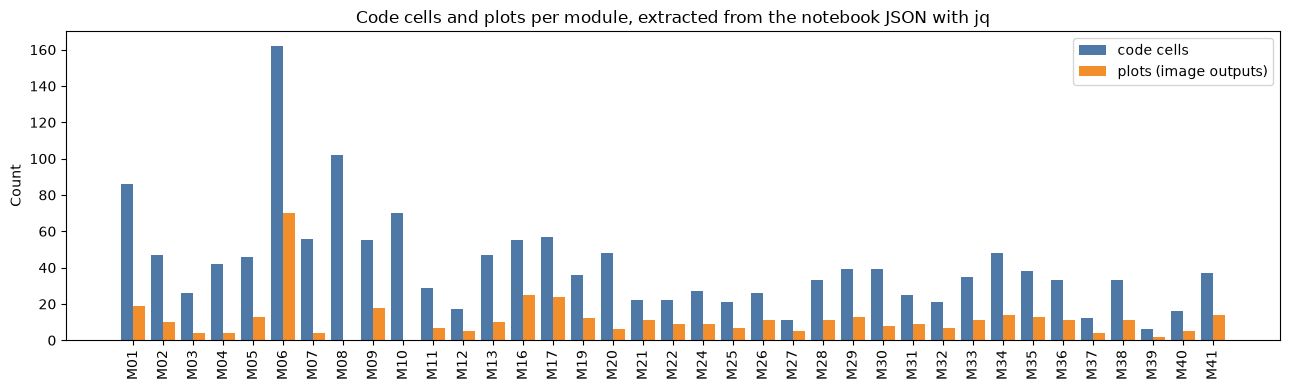

In [6]:
from collections import defaultdict

import matplotlib.pyplot as plt

code_cells, images = defaultdict(int), defaultdict(int)
for module, n_code, n_img in rows:
    code_cells[module] += int(n_code)
    images[module] += int(n_img)
mods = sorted(code_cells)

fig, ax = plt.subplots(figsize=(13, 4))
x = range(len(mods))
ax.bar([i - 0.2 for i in x], [code_cells[m] for m in mods], width=0.4, color="#4E79A7", label="code cells")
ax.bar([i + 0.2 for i in x], [images[m] for m in mods], width=0.4, color="#F28E2B", label="plots (image outputs)")
ax.set_xticks(list(x), mods, rotation=90)
ax.set(title="Code cells and plots per module, extracted from the notebook JSON with jq", ylabel="Count")
ax.legend()
plt.tight_layout()
plt.show()

## 4. JSON Logs

Production services write one JSON object per line (**JSON Lines**). `jq -s` (slurp) reads all lines into one array, so you can aggregate. The log below is synthetic.

In [7]:
import json
import random

random.seed(2)
with open(WORK / "service.jsonl", "w") as f:
    for i in range(500):
        status = random.choices([200, 404, 500], weights=[90, 7, 3])[0]
        f.write(json.dumps({"ts": f"2025-06-01T10:{i // 10:02d}:{i % 60:02d}Z", "path": random.choice(["/api/search", "/api/users", "/health"]),
                            "status": status, "ms": round(random.lognormvariate(3.5, 0.6), 1)}) + "\n")
sh("head -2 service.jsonl")
sh("jq -c 'select(.status >= 500)' service.jsonl | head -3")
sh("jq -s 'group_by(.status) | map({status: .[0].status, n: length})' service.jsonl")
sh("jq -s -r 'group_by(.path)[] | [.[0].path, length, (map(.ms) | add / length | . * 10 | round / 10)] | @tsv' service.jsonl")

$ head -2 service.jsonl
{"ts": "2025-06-01T10:00:00Z", "path": "/api/search", "status": 404, "ms": 17.2}
{"ts": "2025-06-01T10:00:01Z", "path": "/health", "status": 200, "ms": 53.9}
$ jq -c 'select(.status >= 500)' service.jsonl | head -3
{"ts":"2025-06-01T10:02:24Z","path":"/api/search","status":500,"ms":21.8}
{"ts":"2025-06-01T10:04:44Z","path":"/api/users","status":500,"ms":6.9}
{"ts":"2025-06-01T10:12:02Z","path":"/health","status":500,"ms":25.8}
$ jq -s 'group_by(.status) | map({status: .[0].status, n: length})' service.jsonl
[
  {
    "status": 200,
    "n": 452
  },
  {
    "status": 404,
    "n": 37
  },
  {
    "status": 500,
    "n": 11
  }
]
$ jq -s -r 'group_by(.path)[] | [.[0].path, length, (map(.ms) | add / length | . * 10 | round / 10)] | @tsv' service.jsonl
/api/search	166	39.9
/api/users	172	39.3
/health	162	38.6


*Insight: Learn five jq filters (`.field`, `.[]`, `select`, `map`, `group_by`) and you can explore any API response, cloud CLI output (`aws ... --output json`, `kubectl get -o json`, `docker inspect`) or JSON log without writing a script.*

## Real-World Use Case or Analogy

jq is like a **search-and-summary assistant for forms**. You hand over a stack of filled-in forms (JSON documents) and ask: "give me the city of every customer", "only the unpaid orders", "the total per city". The assistant does not care how deeply the fields are nested.

DevOps engineers combine cloud CLIs with jq in automation scripts: `kubectl get pods -o json | jq -r '.items[] | select(.status.phase != "Running") | .metadata.name'` lists every pod that is not running. Data engineers inspect API responses with `curl ... | jq` before they write an ingestion pipeline (M11).